In [1]:
import finesse
from finesse.components import Space, Lens, Laser, Nothing
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'finesse'

In [2]:
def setup_model(f1, f2, d1, d2, d3, visualise=False):
    """
    Creates a simple model of two lenses of focal lengths f1,f2 and three distances, d1, d2, d3.
    """
    M = finesse.model.Model()
    M.lambda0 = 1550e-9 # set the model's wavelength to 1550nm
    
    # first create a laser
    Laser_1550 = Laser("laser_1550", P=1, f=(300e6)/(1550e-9))
    M.add(Laser_1550)
    
    # create two lenses
    
    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    
    M.add([lens_1, lens_2])
    
    # add a target, represented by a 'Nothing' node
    target = Nothing("target")
    M.add(target)
    
    # now create the spaces between components
    s_L_l1 = Space("s_L_l1", portA=Laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2, portB=lens_2.p1, L=d2)
    s_l2_t = Space("s_l2_t", portA=lens_2.p2, portB=target.p1, L=d3)
    
    M.add([s_L_l1, s_l1_l2, s_l2_t])
    
    # check if the output looks alright
    # NB The graph just shows what is connected to what. It doesn't represent physical space.
    if visualise == True:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")
    return M

In [3]:
q_f280apc_1550 = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.6e-3, z=18.07e-3)
print(q_f280apc_1550)
q_f230apc_1550 = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=0.87e-3, z=4.21e-3)

BeamParam(w0=3.6 mm, z=18.07 mm, w=3.6 mm, Rc=38.185 km)


In [ ]:
#setup_model(f1, f2, d1, d2, d3, visualise=False):

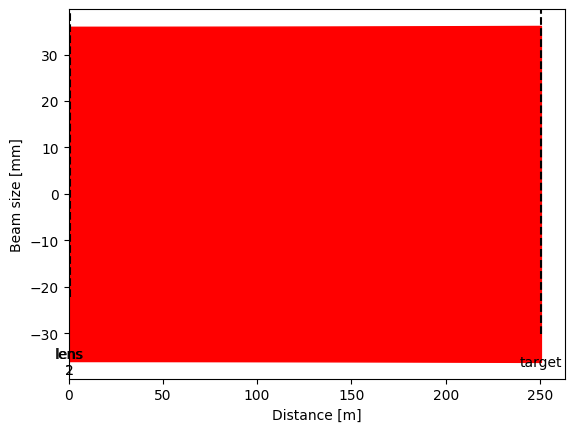

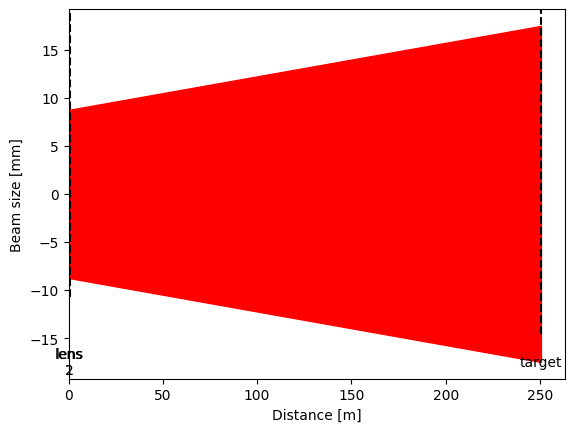

In [4]:
# set up the model with parameters described above
M = setup_model(0.03, 0.3, 0.2, 0.33, 250)

# create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# simulate
sim_f280 = M.propagate_beam(path=beam_path, q_in=q_f280apc_1550, symbolic=True)
sim_f230 = M.propagate_beam(path=beam_path, q_in=q_f230apc_1550)


# plot graphs
sim_f280.plot("beamsize", resolution="all",single_sided=False)
sim_f230.plot("beamsize",single_sided=False)

plt.show()

In [5]:
tel_zs = np.linspace(0.3275, 0.3325, 60)

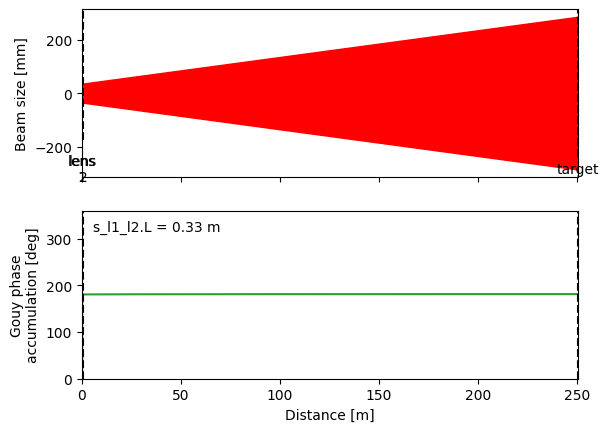

In [6]:
# set up the model with parameters described above
M = setup_model(0.03, 0.3, 0.2, 0.33, 250)

# create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# simulate
sim_f280 = M.propagate_beam(path=beam_path, q_in=q_f280apc_1550, symbolic=True)


fig, axes, anim = sim_f280.animate(
    {M.s_l1_l2.L: tel_zs}, interval=1,
)

In [ ]:
f1=
f2=
d1=0.2
d2=f1+f2
d3=250

In [9]:
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider
import numpy as np

# Set up the model with parameters described above
M = setup_model(0.03, 0.3, 0.2, 0.33, 250)

# Create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# Simulate
sim_f230 = M.propagate_beam(path=beam_path, q_in=q_f230apc_1550, symbolic=True)

# Range of values for tel_zs
tel_zs_range = np.linspace(0.3275, 0.3325, 60)  # Adjust the range and steps as needed

# Function to update the plot based on slider value
def update_plot(tel_zs_value):
    M.s_l1_l2.L = tel_zs_value  # Manually set the parameter
    sim_f230.plot("beamsize",single_sided=False)  # Directly call plot without ax argument

# Create an interactive slider
slider = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(), step=0.0001, value=tel_zs_range.min(), readout_format=".4f")
interact(update_plot, tel_zs_value=slider)

interactive(children=(FloatSlider(value=0.3275, description='tel_zs_value', max=0.3325, min=0.3275, readout_fo…

<function __main__.update_plot(tel_zs_value)>

In [12]:
q_f240apc_1550 = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=1.6e-3, z=7.26e-3)

In [13]:
f1=0.03
f2=0.3
d1=0.2
d2=f1+f2
d3=250

In [14]:
# Set up the model with parameters described above
M = setup_model(f1, f2, d1, d2, d3)

# Create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# Simulate
sim_f240 = M.propagate_beam(path=beam_path, q_in=q_f240apc_1550, symbolic=True)

# Range of values for tel_zs
tel_zs_range = np.linspace(0.3275, 0.3325, 60)  # Adjust the range and steps as needed

# Function to update the plot based on slider value
def update_plot(tel_zs_value):
    M.s_l1_l2.L = tel_zs_value  # Manually set the parameter
    sim_f240.plot("beamsize",single_sided=False)  # Directly call plot without ax argument

# Create an interactive slider
slider = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(), step=0.0001, value=tel_zs_range.min(), readout_format=".4f")
interact(update_plot, tel_zs_value=slider)

interactive(children=(FloatSlider(value=0.3275, description='tel_zs_value', max=0.3325, min=0.3275, readout_fo…

<function __main__.update_plot(tel_zs_value)>

In [15]:
q_f220apc_1550 = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=2.15e-3, z=11.15e-3)

In [16]:
# Set up the model with parameters described above
M = setup_model(f1, f2, d1, d2, d3)

# Create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# Simulate
sim_f220 = M.propagate_beam(path=beam_path, q_in=q_f220apc_1550, symbolic=True)

# Range of values for tel_zs
tel_zs_range = np.linspace(0.3275, 0.3325, 60)  # Adjust the range and steps as needed

# Function to update the plot based on slider value
def update_plot(tel_zs_value):
    M.s_l1_l2.L = tel_zs_value  # Manually set the parameter
    sim_f220.plot("beamsize",single_sided=False)  # Directly call plot without ax argument

# Create an interactive slider
slider = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(), step=0.0001, value=tel_zs_range.min(), readout_format=".4f")
interact(update_plot, tel_zs_value=slider)

interactive(children=(FloatSlider(value=0.3275, description='tel_zs_value', max=0.3325, min=0.3275, readout_fo…

<function __main__.update_plot(tel_zs_value)>